# 03 — Figure Making

Assemble publication-quality multi-panel figures from saved results.

In [7]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline

from src.config import load_config
from src.data_io import load_results
from src import visualization as viz

cfg = load_config()

# Load previously saved results (run batch_process_slices.py first)
results_dir = cfg['paths']['results_dir']
try:
    summary_df = load_results(os.path.join(results_dir, 'all_summaries.csv'))
    print(f'Loaded {len(summary_df)} rows')
except FileNotFoundError:
    print('Run scripts/batch_process_slices.py first to generate results.')
    summary_df = pd.DataFrame()


Run scripts/batch_process_slices.py first to generate results.


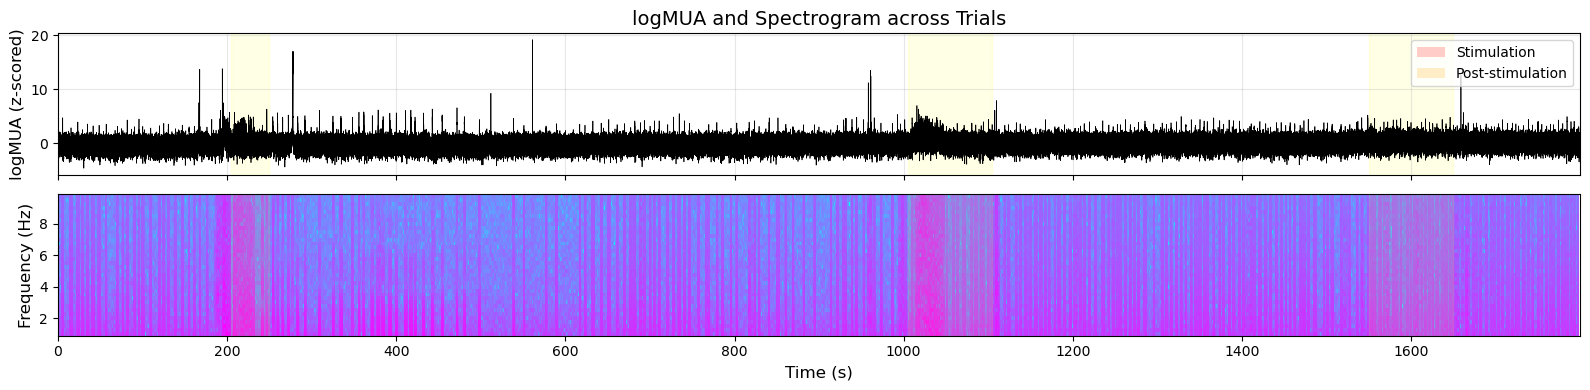

In [14]:
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import signal

from src.preprocessing import extract_features
from src.data_io import load_h5

# Load your data
h5_path = r"C:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\data\processed\20260414_SLICE3_CONTROL_Nathalia.h5"
json_path = r"C:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\data\condition\20260414_SLICE3_CONTROL_Nathalia_trial_definitions.json"

data, meta = load_h5(h5_path)
fs = meta["fs"]

with open(json_path, 'r') as f:
    trials = json.load(f)

# Extract global time window
trial_start_s = trials[0]["start_s"]
trial_end_s = trials[-1]["end_s"]
trial_start_idx = int(trial_start_s * fs)
trial_end_idx = int(trial_end_s * fs)

# Slice data for the full duration
data_slice = data[trial_start_idx:trial_end_idx, :]
lfp_signal = data_slice.mean(axis=1)  # Average across channels

# Extract features (SO, gamma envelope, logMUA) using extract_features
features, t_ds = extract_features(lfp_signal, fs, cfg["preprocessing"])

# logMUA is column 2
log_mua = features[:, 2]

# Compute spectrogram (1-10 Hz) on the original LFP
freqs, times, Sxx = signal.spectrogram(
    lfp_signal,
    fs=fs,
    nperseg=int(fs * 4),  # 4-second windows
    noverlap=int(fs * 3),  # 3-second overlap
)
# Filter to 1-10 Hz
freq_mask = (freqs >= 1) & (freqs <= 10)
freqs = freqs[freq_mask]
Sxx = Sxx[freq_mask, :]

# Convert to dB
Sxx_db = 10 * np.log10(Sxx + 1e-10)

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 4), sharex=True)

# Plot 1: logMUA (z-scored)
ax1.plot(t_ds, log_mua, color='black', linewidth=0.5)
ax1.set_ylabel('logMUA (z-scored)', fontsize=12)
ax1.set_title('logMUA and Spectrogram across Trials', fontsize=14)
ax1.grid(True, alpha=0.3)

# Plot 2: Spectrogram
im = ax2.pcolormesh(
    times,
    freqs,
    Sxx_db,
    shading='auto',
    cmap='cool'
)
ax2.set_ylabel('Frequency (Hz)', fontsize=12)
ax2.set_xlabel('Time (s)', fontsize=12)

# Shade stimulation periods across both plots
colors_stim = {'baseline': None, 'stimulation': 'yellow', 'post_stimulation': 'orange'}

for trial in trials:
    for cond in trial['conditions']:
        if cond['name'] in ['stimulation']:
            # Convert to relative time from trial_start_s
            start_rel = cond['start_s'] - trial_start_s
            end_rel = cond['end_s'] - trial_start_s
            
            color = colors_stim[cond['name']]
            alpha = 0.1
            
            ax1.axvspan(start_rel, end_rel, alpha=alpha, color=color, label=cond['name'])
            ax2.axvspan(start_rel, end_rel, alpha=alpha, color=color)

# Add legend
handles = [
    mpatches.Patch(facecolor='red', alpha=0.2, label='Stimulation'),
    mpatches.Patch(facecolor='orange', alpha=0.2, label='Post-stimulation')
]
ax1.legend(handles=handles, loc='upper right')

# Set x-axis to full trial duration
ax2.set_xlim(0, t_ds[-1])

plt.tight_layout()
plt.show()